# 3. Allocation and Path-Planning Ablation
Compare allocation and route-selection choices using the saved outputs of
notebook 02. No path optimization is rerun here. Rates are model-based
Shannon rates, not measured packet throughput. QoS is checked at the stored
evaluation times; the figures do not establish a continuous-time guarantee.


| Scheme | Route selection | Allocation |
| --- | --- | --- |
| NAIVE | Shortest paths | Equal split |
| +OPTBW | Shortest paths | Optimized contiguous split |
| +SMARTPATH | Candidate-pair search | Equal split |
| JOINT | Candidate-pair search | Optimized contiguous split |

The route search is rerun for +SMARTPATH and JOINT under their respective
allocation rules. Their selected routes and mission durations can differ.
These are comparisons of complete strategies, not a fixed-route causal
estimate of each component. A faster scheme that fails QoS is not a feasible
replacement for a slower scheme that meets it.


## 0. Import


In [1]:
import importlib

import matplotlib.pyplot as plt
import numpy as np

import project_config
importlib.reload(project_config)

from project_config import FIGURES_DIR, PATH_PLANNING_RESULTS_PATH

print("Ablation analysis imports complete")


Ablation analysis imports complete


## 1. Load Results and Validate the Four Schemes


In [2]:
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if not PATH_PLANNING_RESULTS_PATH.exists():
    raise FileNotFoundError("Run notebook 02 first to generate path_planning_results.npz.")

SCHEME_PREFIXES = {
    "NAIVE": "naive",
    "+OPTBW": "optbw",
    "+SMARTPATH": "smartpath",
    "JOINT": "joint",
}

SCHEME_INFO = {
    "NAIVE": ("Shortest", "Equal"),
    "+OPTBW": ("Shortest", "Opt"),
    "+SMARTPATH": ("Comm-aware", "Equal"),
    "JOINT": ("Comm-aware", "Opt"),
}

ARRAY_KEYS = (
    "time_s", "pos1_xy", "pos2_xy",
    "snr1_sc", "snr2_sc", "split_k",
    "rate1_bps", "rate2_bps", "min_rate_bps",
)

SCALAR_KEYS = (
    "r_min_bps", "mean_rate_bps", "mission_time_s",
)

RESULTS = {}

with np.load(PATH_PLANNING_RESULTS_PATH, allow_pickle=False) as data:
    for scheme, prefix in SCHEME_PREFIXES.items():
        RESULTS[scheme] = {
            key: data[f"{prefix}_{key}"]
            for key in ARRAY_KEYS
        }

        for key in SCALAR_KEYS:
            RESULTS[scheme][key] = float(
                data[f"{prefix}_{key}"].item()
            )

    R_QOS_REQUIRED_BPS = float(data["r_qos_required_bps"].item())
    PAIR_SUMMARIES = data["pair_summaries"]

# Read the number of subcarriers from the saved run, not a possibly edited config.
# This notebook visualizes saved results; it does not recompute them.
def validate_results(results, qos_bps):
    if not np.isfinite(qos_bps) or qos_bps <= 0:
        raise ValueError("The saved QoS target must be finite and positive.")
    n_sc = None
    for scheme, result in results.items():
        times = result["time_s"]
        if times.ndim != 1 or len(times) == 0 or not np.all(np.isfinite(times)):
            raise ValueError(f"{scheme}: invalid saved time axis.")
        if times[0] != 0 or np.any(np.diff(times) <= 0):
            raise ValueError(f"{scheme}: time must start at zero and increase strictly.")
        snr = result["snr1_sc"]
        if snr.ndim != 2 or snr.shape[0] != len(times) or snr.shape[1] < 2:
            raise ValueError(f"{scheme}: invalid saved SNR dimensions.")
        if n_sc is None:
            n_sc = snr.shape[1]
        for key, shape in (
            ("snr1_sc", (len(times), n_sc)), ("snr2_sc", (len(times), n_sc)),
            ("pos1_xy", (len(times), 2)), ("pos2_xy", (len(times), 2)),
            ("split_k", (len(times),)), ("rate1_bps", (len(times),)),
            ("rate2_bps", (len(times),)), ("min_rate_bps", (len(times),)),
        ):
            value = result[key]
            if value.shape != shape or not np.all(np.isfinite(value)):
                raise ValueError(f"{scheme}: invalid {key} shape or values.")
            if key.startswith(("snr", "rate", "min_rate")) and np.any(value < 0):
                raise ValueError(f"{scheme}: negative SNR or rate.")
        split = result["split_k"]
        if np.any((split < 1) | (split >= n_sc) | (split != np.floor(split))):
            raise ValueError(f"{scheme}: invalid subcarrier split.")
        bottleneck = np.minimum(result["rate1_bps"], result["rate2_bps"])
        if not np.allclose(result["min_rate_bps"], bottleneck, rtol=1e-9):
            raise ValueError(f"{scheme}: bottleneck rates are inconsistent.")
        for key, expected in (
            ("r_min_bps", bottleneck.min()),
            ("mean_rate_bps", bottleneck.mean()),
            ("mission_time_s", times[-1]),
        ):
            if not np.isclose(result[key], expected, rtol=1e-9):
                raise ValueError(f"{scheme}: saved {key} is inconsistent; rerun notebook 02.")
        result["qos_feasible"] = bool(np.all(bottleneck >= qos_bps))
    return n_sc


N_SC = validate_results(RESULTS, R_QOS_REQUIRED_BPS)
print("Notebook 02 results loaded and validated.")
print(f"QoS target: {R_QOS_REQUIRED_BPS/1e6:.1f} Mbps")
print(f"Route-pair evaluation array: {PAIR_SUMMARIES.shape}")

print()
print(f"{'Scheme':<12}{'Path':<13}{'BW':<8}{'R_min':>10}{'Mean':>10}{'T':>9}  {'Sampled QoS'}")
print("-" * 78)

for scheme, result in RESULTS.items():
    path_mode, bw_mode = SCHEME_INFO[scheme]

    print(
        f"{scheme:<12}{path_mode:<13}{bw_mode:<8}"
        f"{result['r_min_bps']/1e6:>8.2f} M"
        f"{result['mean_rate_bps']/1e6:>8.2f} M"
        f"{result['mission_time_s']:>8.2f} s  "
        f"{'PASS' if result['qos_feasible'] else 'FAIL'}"
    )


Notebook 02 results loaded and validated.
QoS target: 30.0 Mbps
Route-pair evaluation array: (900, 4)

Scheme      Path         BW           R_min      Mean        T  Sampled QoS
------------------------------------------------------------------------------
NAIVE       Shortest     Equal       8.65 M   48.64 M   36.97 s  FAIL
+OPTBW      Shortest     Opt        26.61 M   68.72 M   36.97 s  FAIL
+SMARTPATH  Comm-aware   Equal      21.66 M   64.62 M   41.90 s  FAIL
JOINT       Comm-aware   Opt        33.53 M   75.76 M   40.38 s  PASS


## 2. Subcarrier Share over Time (`00_bw_share.png`)

Each allocation is an integer subcarrier count. Steps display sampled
allocation decisions; they do not model continuous-time scheduling.
The subcarrier count is read from the saved results. Each trace stops at its
own mission completion time; shared axes aid comparison without padding data.


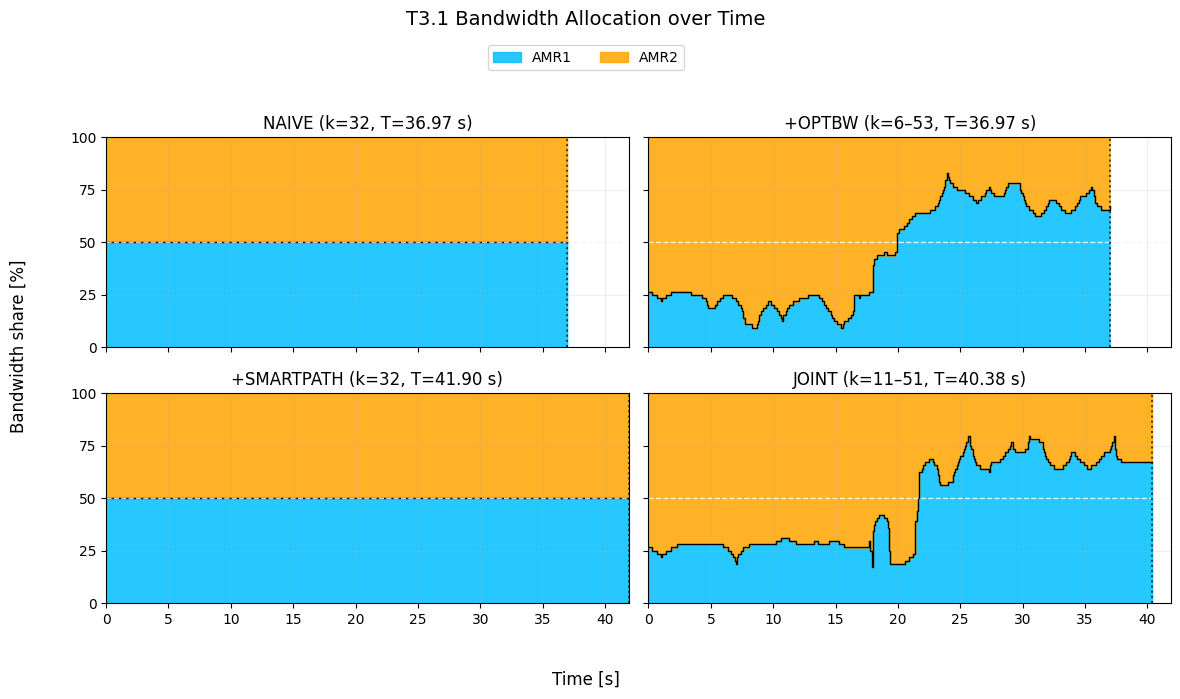

In [3]:
# Schemes included in the comparison
SCHEME_ORDER = ("NAIVE", "+OPTBW", "+SMARTPATH", "JOINT")

# Find the longest mission-completion time.
# Use the longest mission time as the shared x-axis limit for a consistent visual scale.
T_MAX = max(RESULTS[scheme]["mission_time_s"] for scheme in SCHEME_ORDER)

# Create a 2 × 2 panel layout.
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
axes = axes.ravel()

legend_handles = None

for ax, scheme in zip(axes, SCHEME_ORDER):

    # Retrieve the time axis and subcarrier split.
    result = RESULTS[scheme]
    time_s = result["time_s"]
    split_k = result["split_k"]

    # Convert AMR1’s allocated subcarrier count to a percentage.
    amr1_share = 100.0 * split_k / N_SC
    # Shade AMR1’s allocation.
    h1 = ax.fill_between(
        time_s, 0, amr1_share,
        color="deepskyblue", alpha=0.85, label="AMR1", step="post"
    )
    # Shade the remaining allocation for AMR2.
    h2 = ax.fill_between(
        time_s, amr1_share, 100,
        color="orange", alpha=0.85, label="AMR2", step="post"
    )

    # Draw the boundary between the two allocations.
    ax.step(time_s, amr1_share, where="post", color="black", lw=1.0)
    # Mark the equal 50% split with a dashed reference line.
    ax.axhline(50, color="white", ls="--", lw=1.0, alpha=0.8)

    # Mark each scheme’s completion time on the shared x-axis.
    ax.axvline(
        result["mission_time_s"],
        color="black", ls=":", lw=1.4, alpha=0.7
    )

    # Summarize the subcarrier-split range.
    split_min = int(split_k.min())
    split_max = int(split_k.max())

    if split_min == split_max:
        split_text = f"k={split_min}"
    else:
        split_text = f"k={split_min}\u2013{split_max}"

    # Configure the panel title.
    ax.set_title(
        f"{scheme} ({split_text}, T={result['mission_time_s']:.2f} s)"
    )

    # Configure panel axes.
    ax.set_xlim(0, T_MAX)
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.grid(alpha=0.2)

    if legend_handles is None:
        legend_handles = (h1, h2)

# Configure the shared figure labels and legend.
fig.supxlabel("Time [s]")
fig.supylabel("Bandwidth share [%]")
fig.suptitle("T3.1 Bandwidth Allocation over Time", fontsize=14)
fig.legend(
    legend_handles, ("AMR1", "AMR2"),
    loc="upper center", bbox_to_anchor=(0.5, 0.94), ncol=2
)

plt.tight_layout(rect=(0.03, 0.03, 1, 0.90))

BW_SHARE_PATH = FIGURES_DIR / "00_bw_share.png"
fig.savefig(BW_SHARE_PATH, dpi=300, bbox_inches="tight")
plt.show()


## 3. Sampled Bottleneck Rate over Time (`01_throughput.png`)

At each saved time, the bottleneck rate is `min(R1(t), R2(t))`. Each rate is
computed from per-subcarrier SNR using the Shannon formula; no packet-delivery
or coding simulation is performed. `R_min` is the minimum of these bottleneck
rates over the stored times. If `R_min >= 30 Mbps` (the default target), both
AMRs meet QoS at every evaluated time. Connecting lines are visual guides,
not evidence about unsampled times. The mean is an arithmetic sample mean.


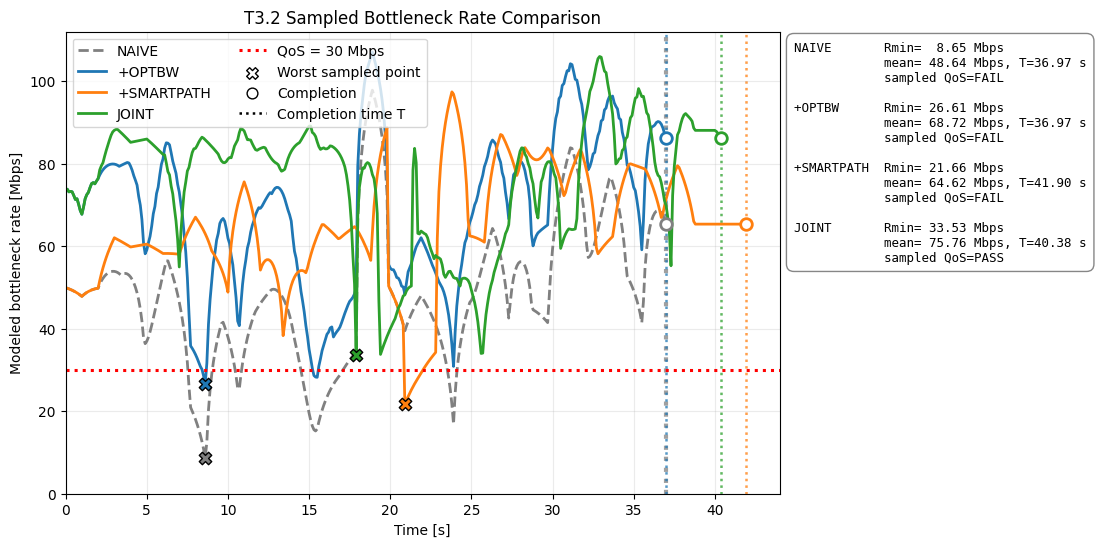

In [4]:
# Schemes included in the comparison
SCHEME_ORDER = ("NAIVE", "+OPTBW", "+SMARTPATH", "JOINT")

PLOT_STYLE = {
    "NAIVE": {"color": "gray", "ls": "--"},
    "+OPTBW": {"color": "tab:blue", "ls": "-"},
    "+SMARTPATH": {"color": "tab:orange", "ls": "-"},
    "JOINT": {"color": "tab:green", "ls": "-"},
}

fig, ax = plt.subplots(figsize=(12, 6))
summary_lines = []

for scheme in SCHEME_ORDER:

    # Retrieve the Task 2 result for this scheme.
    result = RESULTS[scheme]
    time_s = result["time_s"]                        # simulation time
    bottleneck_mbps = result["min_rate_bps"] / 1e6   # modeled bottleneck rate at each time sample
    style = PLOT_STYLE[scheme]

    ax.plot(
        time_s, bottleneck_mbps,
        color=style["color"], ls=style["ls"],
        lw=2.0, label=scheme
    )

    # Mark the time at which R_min occurs with an “X”.
    worst_idx = int(np.argmin(bottleneck_mbps))
    ax.scatter(
        time_s[worst_idx], bottleneck_mbps[worst_idx],
        color=style["color"], edgecolors="black",
        marker="X", s=80, zorder=5
    )

    # Mark mission completion with an open circle.
    ax.scatter(
        time_s[-1], bottleneck_mbps[-1],
        facecolors="white", edgecolors=style["color"],
        marker="o", s=70, linewidths=2, zorder=5
    )

    # Draw a vertical dotted line at the mission-completion time.
    ax.axvline(
        result["mission_time_s"],
        color=style["color"], ls=":",
        lw=3.0 if scheme == "NAIVE" else 1.8,
        alpha=0.75, zorder=1
    )

    # Build the summary text displayed to the right of the plot.
    summary_lines.append(
        f"{scheme:<11} "
        f"Rmin={result['r_min_bps']/1e6:6.2f} Mbps\n"
        f"{'':11} mean={result['mean_rate_bps']/1e6:6.2f} Mbps, "
        f"T={result['mission_time_s']:5.2f} s\n"
        f"{'':11} sampled QoS={'PASS' if result['qos_feasible'] else 'FAIL'}"
    )

# Draw the QoS target as a red horizontal dotted line.
ax.axhline(
    R_QOS_REQUIRED_BPS / 1e6,
    color="red", ls=":", lw=2.2,
    label=f"QoS = {R_QOS_REQUIRED_BPS/1e6:.0f} Mbps"
)

# Add marker meanings to the legend.
ax.scatter(
    [], [], color="white", edgecolors="black",
    marker="X", s=70, label="Worst sampled point"
)
ax.scatter(
    [], [], facecolors="white", edgecolors="black",
    marker="o", s=60, label="Completion"
)
ax.plot(
    [], [], color="black", ls=":", lw=1.8,
    label="Completion time T"
)

# Configure axes and title.
ax.set(
    xlabel="Time [s]",
    ylabel="Modeled bottleneck rate [Mbps]",
    title="T3.2 Sampled Bottleneck Rate Comparison"
)
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.25)
ax.legend(loc="upper left", ncol=2)

# Add the right-hand summary box.
ax.text(
    1.02, 0.98, "\n\n".join(summary_lines),
    transform=ax.transAxes,
    ha="left", va="top",
    fontsize=9, family="monospace",
    bbox={
        "facecolor": "white",
        "edgecolor": "gray",
        "alpha": 0.95,
        "boxstyle": "round,pad=0.6",
    }
)

fig.subplots_adjust(right=0.72)

THROUGHPUT_PATH = FIGURES_DIR / "01_throughput.png"
fig.savefig(THROUGHPUT_PATH, dpi=300, bbox_inches="tight")
plt.show()


## 4. Strategy Contrasts (`10_ablation_bars.png`)

Compare minimum sampled bottleneck rate, mean sampled bottleneck rate, and
mission completion time. These are distinct metrics: `R_min` is a scalar
minimum, so the mean is not a "mean R_min". Every strategy is summarized over
its own mission horizon. QoS feasibility is shown alongside the metrics.

All displayed differences are explicitly first strategy minus second strategy.
Rate increases and mission-time decreases are preferable, subject to meeting
QoS. The second differences quantify non-additivity in this experiment;
reselected routes and different mission horizons prevent interpreting them
as fixed-route causal effects or a universal synergy claim.


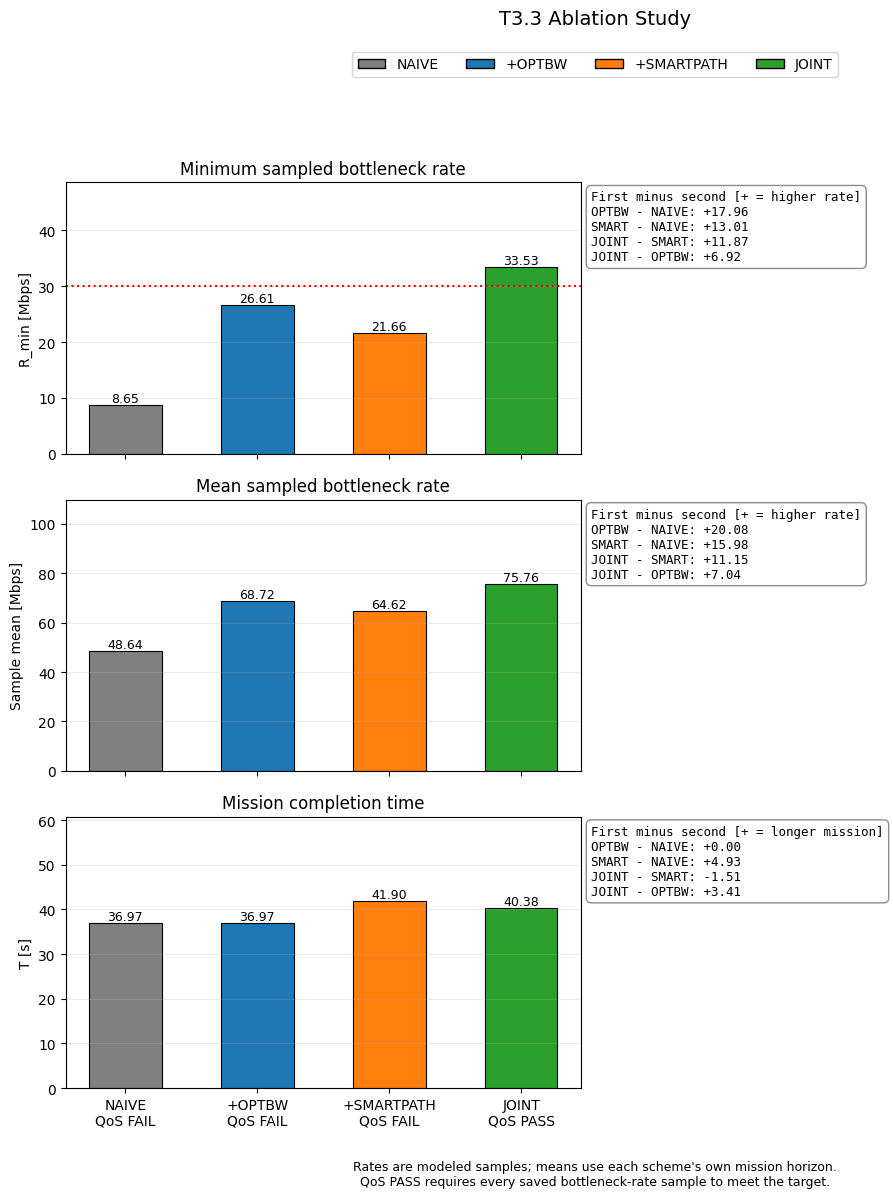

In [5]:
from matplotlib.patches import Patch

# Colors assigned to each scheme
SCHEME_ORDER = ("NAIVE", "+OPTBW", "+SMARTPATH", "JOINT")
BAR_COLORS = ("gray", "tab:blue", "tab:orange", "tab:green")

# Minimum sampled bottleneck rate for each scheme [Mbps]
rmin_values = np.array([
    RESULTS[scheme]["r_min_bps"] / 1e6
    for scheme in SCHEME_ORDER
])

# Arithmetic mean of the sampled bottleneck rates for each scheme [Mbps]
mean_values = np.array([
    RESULTS[scheme]["mean_rate_bps"] / 1e6
    for scheme in SCHEME_ORDER
])

# Mission-completion time T for each scheme
time_values = np.array([
    RESULTS[scheme]["mission_time_s"]
    for scheme in SCHEME_ORDER
])

# (panel title, y-axis label, values, whether higher is better)
METRICS = (
    ("Minimum sampled bottleneck rate", "R_min [Mbps]", rmin_values, True),
    ("Mean sampled bottleneck rate", "Sample mean [Mbps]", mean_values, True),
    ("Mission completion time", "T [s]", time_values, False),
)


# Draw three vertically stacked panels: R_min, mean rate, then T.
fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

for ax, (title, ylabel, values, higher_is_better) in zip(axes, METRICS):
    bars = ax.bar(
        SCHEME_ORDER, values,
        color=BAR_COLORS, edgecolor="black",
        linewidth=0.8, width=0.55
    )

    # Annotate each bar with its value.
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.2f}",
            ha="center", va="bottom",
            fontsize=9
        )

    # Strategy contrasts; route-search strategies may select different paths.
    sense = "+ = higher rate" if higher_is_better else "+ = longer mission"
    delta_text = (
        f"First minus second [{sense}]\n"
        f"OPTBW - NAIVE: {values[1]-values[0]:+.2f}\n"
        f"SMART - NAIVE: {values[2]-values[0]:+.2f}\n"
        f"JOINT - SMART: {values[3]-values[2]:+.2f}\n"
        f"JOINT - OPTBW: {values[3]-values[1]:+.2f}"
    )

    ax.text(
        1.02, 0.97, delta_text,
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=9, family="monospace",
        bbox={
            "facecolor": "white",
            "edgecolor": "gray",
            "alpha": 0.9,
            "boxstyle": "round,pad=0.4",
        }
    )

    if ylabel == "R_min [Mbps]":
        ax.axhline(R_QOS_REQUIRED_BPS / 1e6, color="red", linestyle=":", linewidth=1.5)
    ax.set_xticks(range(len(SCHEME_ORDER)), [
        f"{scheme}\nQoS {'PASS' if RESULTS[scheme]['qos_feasible'] else 'FAIL'}"
        for scheme in SCHEME_ORDER
    ])
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(values) * 1.45)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("T3.3 Ablation Study", fontsize=14, y=0.995)

legend_handles = [
    Patch(facecolor=color, edgecolor="black", label=scheme)
    for scheme, color in zip(SCHEME_ORDER, BAR_COLORS)
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.965),
    ncol=4,
    frameon=True,
)

fig.text(
    0.5, 0.015,
    "Rates are modeled samples; means use each scheme's own mission horizon.\n"
    "QoS PASS requires every saved bottleneck-rate sample to meet the target.",
    ha="center", fontsize=9
)

plt.tight_layout(rect=(0, 0.05, 0.76, 0.91))

ABLATION_PATH = FIGURES_DIR / "10_ablation_bars.png"
fig.savefig(ABLATION_PATH, dpi=300, bbox_inches="tight")
plt.show()


In [6]:
# Quantify the gain from each element in isolation.
delta_add_optbw = rmin_values[1] - rmin_values[0]
delta_add_smart = rmin_values[2] - rmin_values[0]
delta_add_sum = delta_add_optbw + delta_add_smart

# Quantify the gain achieved by the full JOINT method.
delta_joint = rmin_values[3] - rmin_values[0]

interaction = delta_joint - delta_add_sum

print("\n[R_min contribution analysis]")
print(f"OptBW-only gain       : {delta_add_optbw:+.2f} Mbps")
print(f"SmartPath-only gain   : {delta_add_smart:+.2f} Mbps")
print(f"Sum of isolated gains   : {delta_add_sum:+.2f} Mbps")
print(f"Observed JOINT gain       : {delta_joint:+.2f} Mbps")
print(f"Interaction           : {interaction:+.2f} Mbps")

print("This is a strategy-level interaction contrast; routes are reselected.")
print("It does not establish a fixed-route causal effect or general synergy.")



[R_min contribution analysis]
OptBW-only gain       : +17.96 Mbps
SmartPath-only gain   : +13.01 Mbps
Sum of isolated gains   : +30.97 Mbps
Observed JOINT gain       : +24.88 Mbps
Interaction           : -6.09 Mbps
This is a strategy-level interaction contrast; routes are reselected.
It does not establish a fixed-route causal effect or general synergy.
